#Importando dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


#Processando e limpando dataset

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("/kaggle/input/titanic-dataset/Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
#Removendo colunas
df_aux = df
df_aux = df_aux.drop(columns=['Name', 'Cabin', 'Ticket', 'PassengerId'])
df_aux.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [7]:
df_aux['Embarked'].value_counts()

,count
Embarked,
S,644
C,168
Q,77


In [8]:
#Substituindo pelo object que mais aparece
df_aux['Embarked'] = df_aux['Embarked'].fillna(df_aux['Embarked'].mode()[0])

In [9]:
df_aux['Embarked'].value_counts()

,count
Embarked,
S,646
C,168
Q,77


In [10]:
#Substituindo os valores nulos pela média da idade
df_aux['Age'] = df_aux['Age'].fillna(df_aux['Age'].mean())
#Transformando os valores de float para int
df_aux['Age'] = df_aux['Age'].astype(int)
df_aux.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22,1,0,7.2500,S
1,1,1,female,38,1,0,71.2833,C
2,1,3,female,26,0,0,7.9250,S
3,1,1,female,35,1,0,53.1000,S
4,0,3,male,35,0,0,8.0500,S


In [11]:
#Transforma a classe 'Sex' em encoding
df_aux['Sex'].isnull().sum()
sex_dummies = pd.get_dummies(df_aux['Sex'], prefix='Sex')
df_aux = pd.concat([df_aux, sex_dummies], axis=1)
df_aux = df_aux.drop(columns=['Sex'])
df_aux.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male
0,0,3,22,1,0,7.2500,S,False,True
1,1,1,38,1,0,71.2833,C,True,False
2,1,3,26,0,0,7.9250,S,True,False
3,1,1,35,1,0,53.1000,S,True,False
4,0,3,35,0,0,8.0500,S,False,True


In [12]:
#Transforma a classe "Embarked" em encoding
df_aux['Embarked'].isnull().sum()
embarked_dummies = pd.get_dummies(df_aux['Embarked'], prefix='Embarked')
df_aux = pd.concat([df_aux, embarked_dummies], axis=1)
df_aux = df_aux.drop(columns=['Embarked'])
df_aux.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22,1,0,7.2500,False,True,False,False,True
1,1,1,38,1,0,71.2833,True,False,True,False,False
2,1,3,26,0,0,7.9250,True,False,False,False,True
3,1,1,35,1,0,53.1000,True,False,False,False,True
4,0,3,35,0,0,8.0500,False,True,False,False,True


In [13]:
#Criando nova coluna para simplifica 'SibSp' e 'Parch'
df_aux['FamilySize'] = df_aux['SibSp'] + df_aux['Parch'] + 1
df_aux = df_aux.drop(columns=['SibSp', 'Parch'])
df_aux.head()

,Survived,Pclass,Age,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,FamilySize
0,0,3,22,7.2500,False,True,False,False,True,2
1,1,1,38,71.2833,True,False,True,False,False,2
2,1,3,26,7.9250,True,False,False,False,True,1
3,1,1,35,53.1000,True,False,False,False,True,2
4,0,3,35,8.0500,False,True,False,False,True,1


In [14]:
#Criando coluna para sabe se a pessoa estava acomponhado ou não
df_aux['IsAlone'] = df_aux['FamilySize'].apply(lambda x: 1 if x == 1 else 0)
df_aux = df_aux.drop(columns=['FamilySize'])
df_aux.head()

,Survived,Pclass,Age,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,IsAlone
0,0,3,22,7.2500,False,True,False,False,True,0
1,1,1,38,71.2833,True,False,True,False,False,0
2,1,3,26,7.9250,True,False,False,False,True,1
3,1,1,35,53.1000,True,False,False,False,True,0
4,0,3,35,8.0500,False,True,False,False,True,1


In [15]:
bool_cols = df_aux.select_dtypes(include='bool').columns
df_aux[bool_cols] = df_aux[bool_cols].astype(int)
df_aux.head()

,Survived,Pclass,Age,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,IsAlone
0,0,3,22,7.2500,0,1,0,0,1,0
1,1,1,38,71.2833,1,0,1,0,0,0
2,1,3,26,7.9250,1,0,0,0,1,1
3,1,1,35,53.1000,1,0,0,0,1,0
4,0,3,35,8.0500,0,1,0,0,1,1


In [16]:
df_aux['Fare'].isnull().sum()

np.int64(0)

#Análise Exploratória (EDA)

In [17]:
porcentagem = df_aux['Survived'].mean()
print(f'Apenas {round(df_aux['Survived'].mean() * 100, 2)}% sobreviveram.' )

Apenas 38.38% sobreviveram.


In [18]:
df_aux.groupby('Sex_female')['Survived'].mean()
print(f'Apenas {round(df_aux.groupby("Sex_female")["Survived"].mean()[1] * 100, 2)}% das mulheres sobreviveram.')
print(f'Apenas {round(df_aux.groupby("Sex_female")["Survived"].mean()[0] * 100, 2)}% dos homens sobreviveram.')

Apenas 74.2% das mulheres sobreviveram.
Apenas 18.89% dos homens sobreviveram.


In [19]:
df_aux.groupby('Pclass')['Survived'].mean()
print(f'Observa-se uma forte correlação entre classe social e taxa de sobrevivência. Passageiros da 1ª classe apresentaram maior probabilidade de sobrevivência ({round(df_aux.groupby('Pclass')['Survived'].mean()[1]*100,2)}), enquanto passageiros da 3ª classe tiveram a menor taxa ({round(df_aux.groupby('Pclass')['Survived'].mean()[3]*100,2)}). Esse padrão sugere desigualdade no acesso aos recursos de evacuação durante o desastre.')

Observa-se uma forte correlação entre classe social e taxa de sobrevivência. Passageiros da 1ª classe apresentaram maior probabilidade de sobrevivência (62.96), enquanto passageiros da 3ª classe tiveram a menor taxa (24.24). Esse padrão sugere desigualdade no acesso aos recursos de evacuação durante o desastre.


In [20]:
df_aux.groupby('IsAlone')['Survived'].mean()

,Survived
IsAlone,
0,0.505650
1,0.303538


In [21]:
df_aux['AgeGroup'] = pd.cut(
    df_aux['Age'],
    bins=[0, 12, 18, 40, 60, 100],
    labels=['Criança', 'Adolescente', 'Adulto', 'Meia-idade', 'Idoso']
)
df_aux.groupby('AgeGroup')['Survived'].mean()

/tmp/ipykernel_25128/3233601164.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_aux.groupby('AgeGroup')['Survived'].mean()


,Survived
AgeGroup,
Criança,0.532258
Adolescente,0.428571
Adulto,0.359272
Meia-idade,0.396825
Idoso,0.227273


#Gráficos

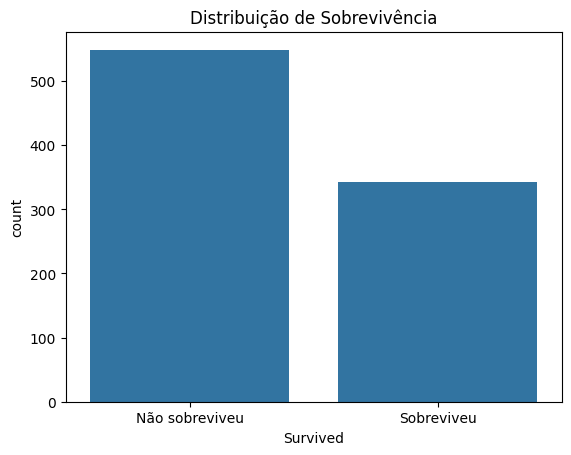

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Survived', data=df_aux)
plt.xticks([0,1], ['Não sobreviveu', 'Sobreviveu'])
plt.title('Distribuição de Sobrevivência')
plt.show()

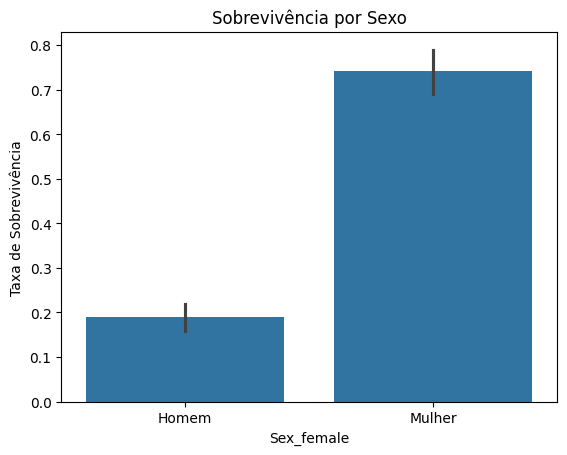

In [23]:
sns.barplot(x='Sex_female', y='Survived', data=df_aux)
plt.xticks([0,1], ['Homem', 'Mulher'])
plt.title('Sobrevivência por Sexo')
plt.ylabel('Taxa de Sobrevivência')
plt.show()

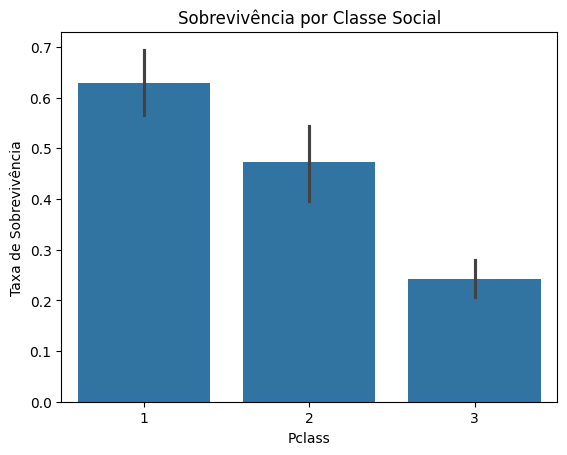

In [24]:
sns.barplot(x='Pclass', y='Survived', data=df_aux)
plt.title('Sobrevivência por Classe Social')
plt.ylabel('Taxa de Sobrevivência')
plt.show()

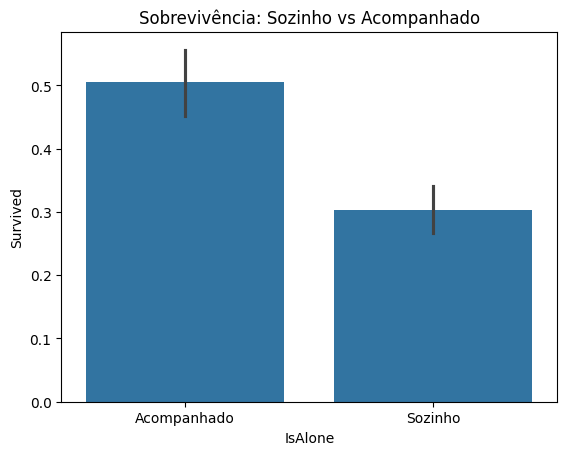

In [25]:
sns.barplot(x='IsAlone', y='Survived', data=df_aux)
plt.xticks([0,1], ['Acompanhado', 'Sozinho'])
plt.title('Sobrevivência: Sozinho vs Acompanhado')
plt.show()

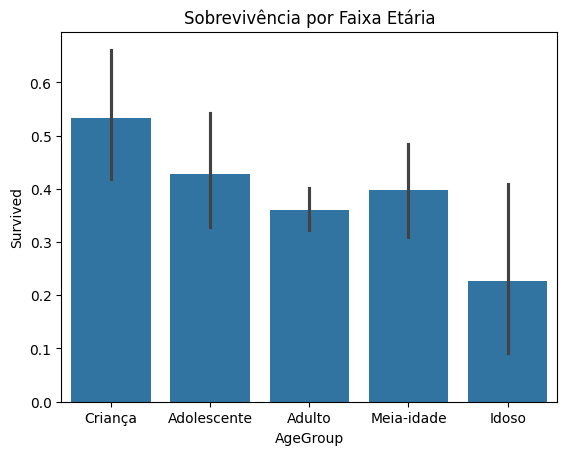

In [26]:
sns.barplot(x='AgeGroup', y='Survived', data=df_aux)
plt.title('Sobrevivência por Faixa Etária')
plt.show()

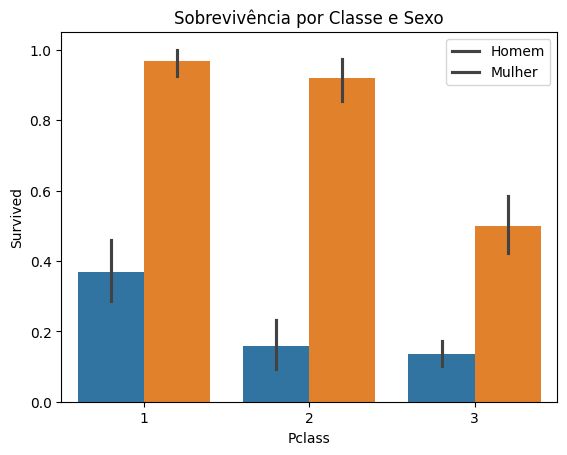

In [27]:
sns.barplot(x='Pclass', y='Survived', hue='Sex_female', data=df_aux)
plt.legend(['Homem', 'Mulher'])
plt.title('Sobrevivência por Classe e Sexo')
plt.show()

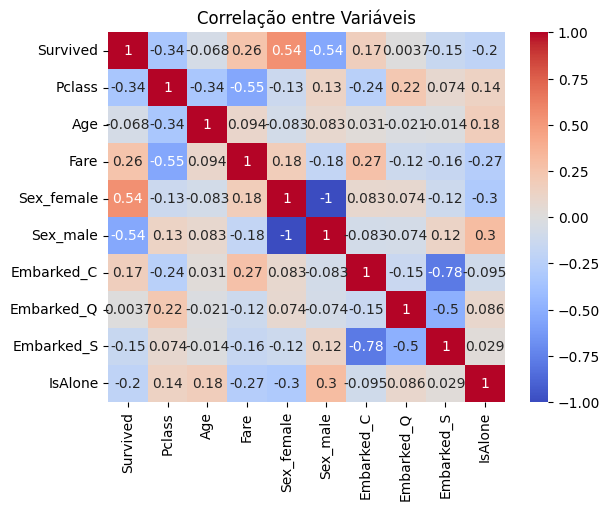

In [28]:
import numpy as np

corr = df_aux.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlação entre Variáveis')
plt.show()

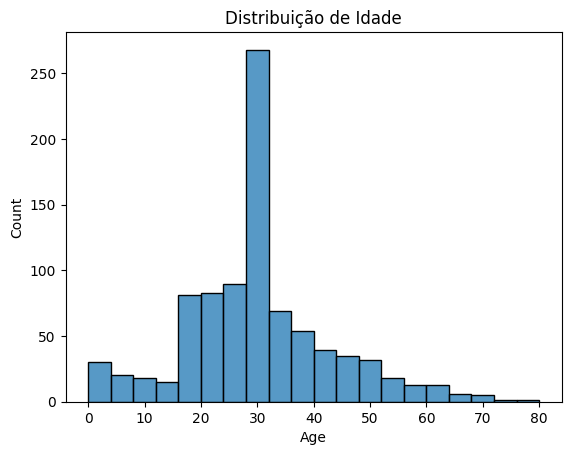

In [29]:
sns.histplot(df_aux['Age'], bins=20)
plt.title('Distribuição de Idade')
plt.show()

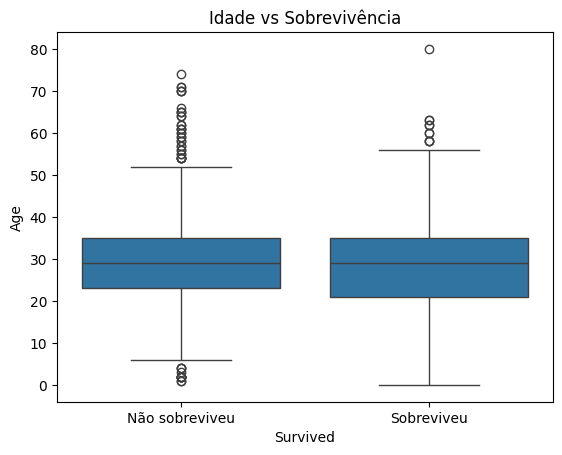

In [30]:
sns.boxplot(x='Survived', y='Age', data=df_aux)
plt.xticks([0,1], ['Não sobreviveu', 'Sobreviveu'])
plt.title('Idade vs Sobrevivência')
plt.show()

# **Análise Exploratória de Dados do Dataset Titanic**

## **Resumo**

Este estudo apresenta uma análise exploratória de dados (EDA) aplicada ao dataset Titanic, com o objetivo de identificar os principais fatores que influenciaram a sobrevivência dos passageiros. Foram realizadas etapas de pré-processamento, engenharia de atributos, análise estatística e visualizações gráficas. Os resultados indicam que variáveis como sexo, classe social e presença de familiares tiveram impacto significativo na probabilidade de sobrevivência, enquanto a idade apresentou influência moderada.

---

## **1. Introdução**

O naufrágio do Titanic é um dos eventos históricos mais estudados em ciência de dados, sendo amplamente utilizado para análise preditiva e exploração de padrões. Este trabalho busca compreender quais características dos passageiros influenciaram suas chances de sobrevivência, utilizando técnicas de análise exploratória de dados.

---

## **2. Metodologia**

O processo de análise foi dividido em cinco etapas principais:

### **2.1 Importação dos Dados**

Os dados foram carregados em um DataFrame utilizando a biblioteca Pandas, contendo variáveis como idade, sexo, classe, tarifa e status de sobrevivência.

---

### **2.2 Limpeza e Pré-processamento**

Nesta etapa, foram realizadas transformações para preparar os dados para análise:

* Conversão de variáveis categóricas em numéricas utilizando One-Hot Encoding (ex: sexo e porto de embarque).
* Remoção de colunas irrelevantes.
* Conversão de valores booleanos para inteiros.

---

### **2.3 Engenharia de Atributos**

Foram criadas novas variáveis para enriquecer a análise:

* **FamilySize**: soma do número de familiares a bordo.
* **IsAlone**: variável binária indicando se o passageiro estava sozinho.
* **AgeGroup**: categorização da idade em faixas (criança, adolescente, adulto, meia-idade e idoso).

---

### **2.4 Análise Exploratória de Dados (EDA)**

Foram utilizadas estatísticas descritivas e agrupamentos (`groupby`) para identificar padrões entre variáveis e a sobrevivência.

---

### **2.5 Visualização de Dados**

Gráficos foram gerados com as bibliotecas Seaborn e Matplotlib, incluindo:

* Gráficos de contagem
* Gráficos de barras
* Heatmap de correlação
* Histogramas e boxplots

---

## **3. Resultados**

A análise revelou os seguintes padrões:

### **3.1 Taxa Geral de Sobrevivência**

Apenas aproximadamente **38,38%** dos passageiros sobreviveram ao desastre.

---

### **3.2 Influência do Sexo**

Observou-se uma diferença significativa entre os sexos:

* Mulheres: aproximadamente **74%** sobreviveram
* Homens: aproximadamente **19%** sobreviveram

Isso sugere a aplicação do protocolo de prioridade para mulheres e crianças.

---

### **3.3 Influência da Classe Social**

A classe do passageiro apresentou forte relação com a sobrevivência:

* 1ª classe: maior taxa de sobrevivência (~63%)
* 3ª classe: menor taxa (~24%)

Esse resultado evidencia a influência de fatores socioeconômicos.

---

### **3.4 Influência da Presença de Familiares**

A variável *IsAlone* indicou que:

* Passageiros acompanhados tiveram maior taxa de sobrevivência (~50%)
* Passageiros sozinhos tiveram menor taxa (~30%)

Isso sugere que a presença de familiares pode ter contribuído para melhores chances de resgate.

---

### **3.5 Influência da Idade**

A idade apresentou impacto moderado:

* Crianças tiveram maior taxa de sobrevivência (~53%)
* Idosos apresentaram menor taxa (~22%)

Apesar disso, a idade não se mostrou um fator tão determinante quanto sexo e classe social.

---

### **3.6 Análise de Correlação**

O mapa de correlação indicou que:

* A variável sexo feminino possui forte correlação positiva com sobrevivência.
* A classe social possui correlação negativa (quanto menor a classe, menor a chance de sobreviver).
* Estar sozinho também apresenta correlação negativa.

---

## **4. Discussão**

Os resultados confirmam padrões históricos conhecidos, como a priorização de mulheres e crianças e a influência de fatores socioeconômicos no acesso aos botes salva-vidas. Além disso, a análise mostra que a estrutura familiar teve papel relevante, possivelmente devido à cooperação entre passageiros.

---

## **5. Conclusão**

Este estudo demonstrou que a sobrevivência no Titanic foi influenciada principalmente por:

* Sexo (mulheres tiveram maior chance de sobrevivência)
* Classe social (passageiros de classes mais altas tiveram vantagem)
* Presença de familiares (acompanhamento aumentou a probabilidade de sobrevivência)

A idade apresentou influência secundária, indicando maior proteção a crianças, mas não sendo um fator determinante isolado.

---

## **6. Trabalhos Futuros**

Para aprofundar a análise, recomenda-se:

* Aplicação de modelos de machine learning para previsão de sobrevivência
* Análise de interação entre variáveis (ex: sexo + classe)
* Tratamento mais avançado de dados ausentes
* Testes estatísticos para validação dos insights

---

## **Palavras-chave**

Análise de Dados, Titanic, Machine Learning, EDA, Visualização de Dados
